# BERTweet Fine-Tuning

Fine-tunes the public `vinai/bertweet-base` transformer with stratified cross-validation and produces blend-ready OOF and test probabilities.

## Overview

- Fine-tunes `vinai/bertweet-base`.
- Supports CUDA, Apple Silicon MPS, and CPU execution.
- Uses stratified folds, early stopping, and OOF threshold selection.
- Writes `bertweet_submission.csv` and `artifacts/bertweet*/predictions.npz`.
- Includes dataset and model-artifact diagnostics for validation review.

Source script: `bertweet_solution.py`


## Environment Setup

### Required Packages

Install the project dependencies from the repository root:

```bash
python3 -m venv .venv
.venv/bin/pip install -r requirements.txt
```

### Notebook Path

Run notebooks from the repository root when possible. If you open a notebook from `notebooks/`, the root-detection cell resolves the parent project directory automatically.

### Hardware Requirements

- CPU is sufficient for sparse, ensemble, and blend notebooks.
- A CUDA or Apple Silicon MPS GPU is recommended for BERTweet fine-tuning.
- 8 GB RAM is the minimum; 16 GB or more is recommended.


## What This Notebook Does

- Trains the transformer model only on supplied training labels.
- Optimizes the F1 threshold from OOF predictions.
- Produces high-quality probabilities for ensemble blending.


## Run Setup

Run notebooks from the repository root when possible. If you open a notebook from the `notebooks/` folder, the project-root detection cell below will still resolve the parent project directory.


In [1]:
from __future__ import annotations

# Optional setup for a fresh local runtime. Uncomment if the project .venv is missing.
# %pip install -r requirements.txt
# %pip install -r ../requirements.txt

print("This notebook uses packages from the project .venv (see the import cell).")
print("If torch is still missing, select the Competition (.venv) kernel and rerun.")

# Result summary: output for notebook cell 4
import importlib.util as _importlib_util
import pandas as _setup_pd
_setup_packages = ["torch", "transformers", "accelerate", "pandas", "matplotlib", "seaborn"]
_setup_pd.DataFrame(
    {
        "package": _setup_packages,
        "available": [_importlib_util.find_spec(name) is not None for name in _setup_packages],
    }
).set_index("package")


This notebook uses packages from the project .venv (see the import cell).
If torch is still missing, select the Competition (.venv) kernel and rerun.


,available
package,
torch,True
transformers,True
accelerate,True
pandas,True
matplotlib,True
seaborn,True


## Imports And Configuration


In [2]:
import argparse
import json
import os
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from urllib.parse import unquote_plus

try:
    ROOT = Path(__file__).resolve().parent
except NameError:
    ROOT = Path.cwd()
    if not (ROOT / "data/train.csv").exists() and (ROOT.parent / "data/train.csv").exists():
        ROOT = ROOT.parent

venv_site = ROOT / ".venv" / "lib" / f"python{sys.version_info.major}.{sys.version_info.minor}" / "site-packages"
if venv_site.exists() and str(venv_site) not in sys.path:
    sys.path.insert(0, str(venv_site))

import numpy as np
import pandas as pd
import torch
import transformers
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

DEFAULT_MODEL = "vinai/bertweet-base"
print(f"Python: {sys.executable}")
print(f"torch {torch.__version__}")
print(f"Project root: {ROOT}")

# Result summary: output for notebook cell 6

pd.Series(
    {
        "project_root": str(ROOT),
        "train_file_exists": (ROOT / "data/train.csv").exists(),
        "test_file_exists": (ROOT / "data/test.csv").exists(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "selected_device": str(device_for_run()) if "device_for_run" in globals() else "not selected yet",
    },
    name="runtime",
)


/Users/aftabhossain/Downloads/Competition/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /Users/aftabhossain/Downloads/Competition/.venv/bin/python
torch 2.13.0
Project root: /Users/aftabhossain/Downloads/Competition


project_root         /Users/aftabhossain/Downloads/Competition
train_file_exists                                         True
test_file_exists                                          True
torch                                                   2.13.0
transformers                                            5.16.1
selected_device                               not selected yet
Name: runtime, dtype: object

## Visualization Setup

The following cells use a shared plotting theme so exploratory charts, validation curves, and artifact diagnostics read consistently across the notebook series.


In [3]:
# Codex visualization block: shared plotting style
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "savefig.dpi": 180,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "axes.edgecolor": "#d1d5db",
        "grid.color": "#e5e7eb",
        "legend.frameon": False,
    }
)

CLASS_COLORS = {
    "Not disaster": "#2563eb",
    "Disaster": "#dc2626",
    "Train": "#2563eb",
    "Test": "#059669",
}



## Dataset Visual Diagnostics

These charts summarize class balance, metadata coverage, tweet length distribution, and high-signal keywords before model fitting.


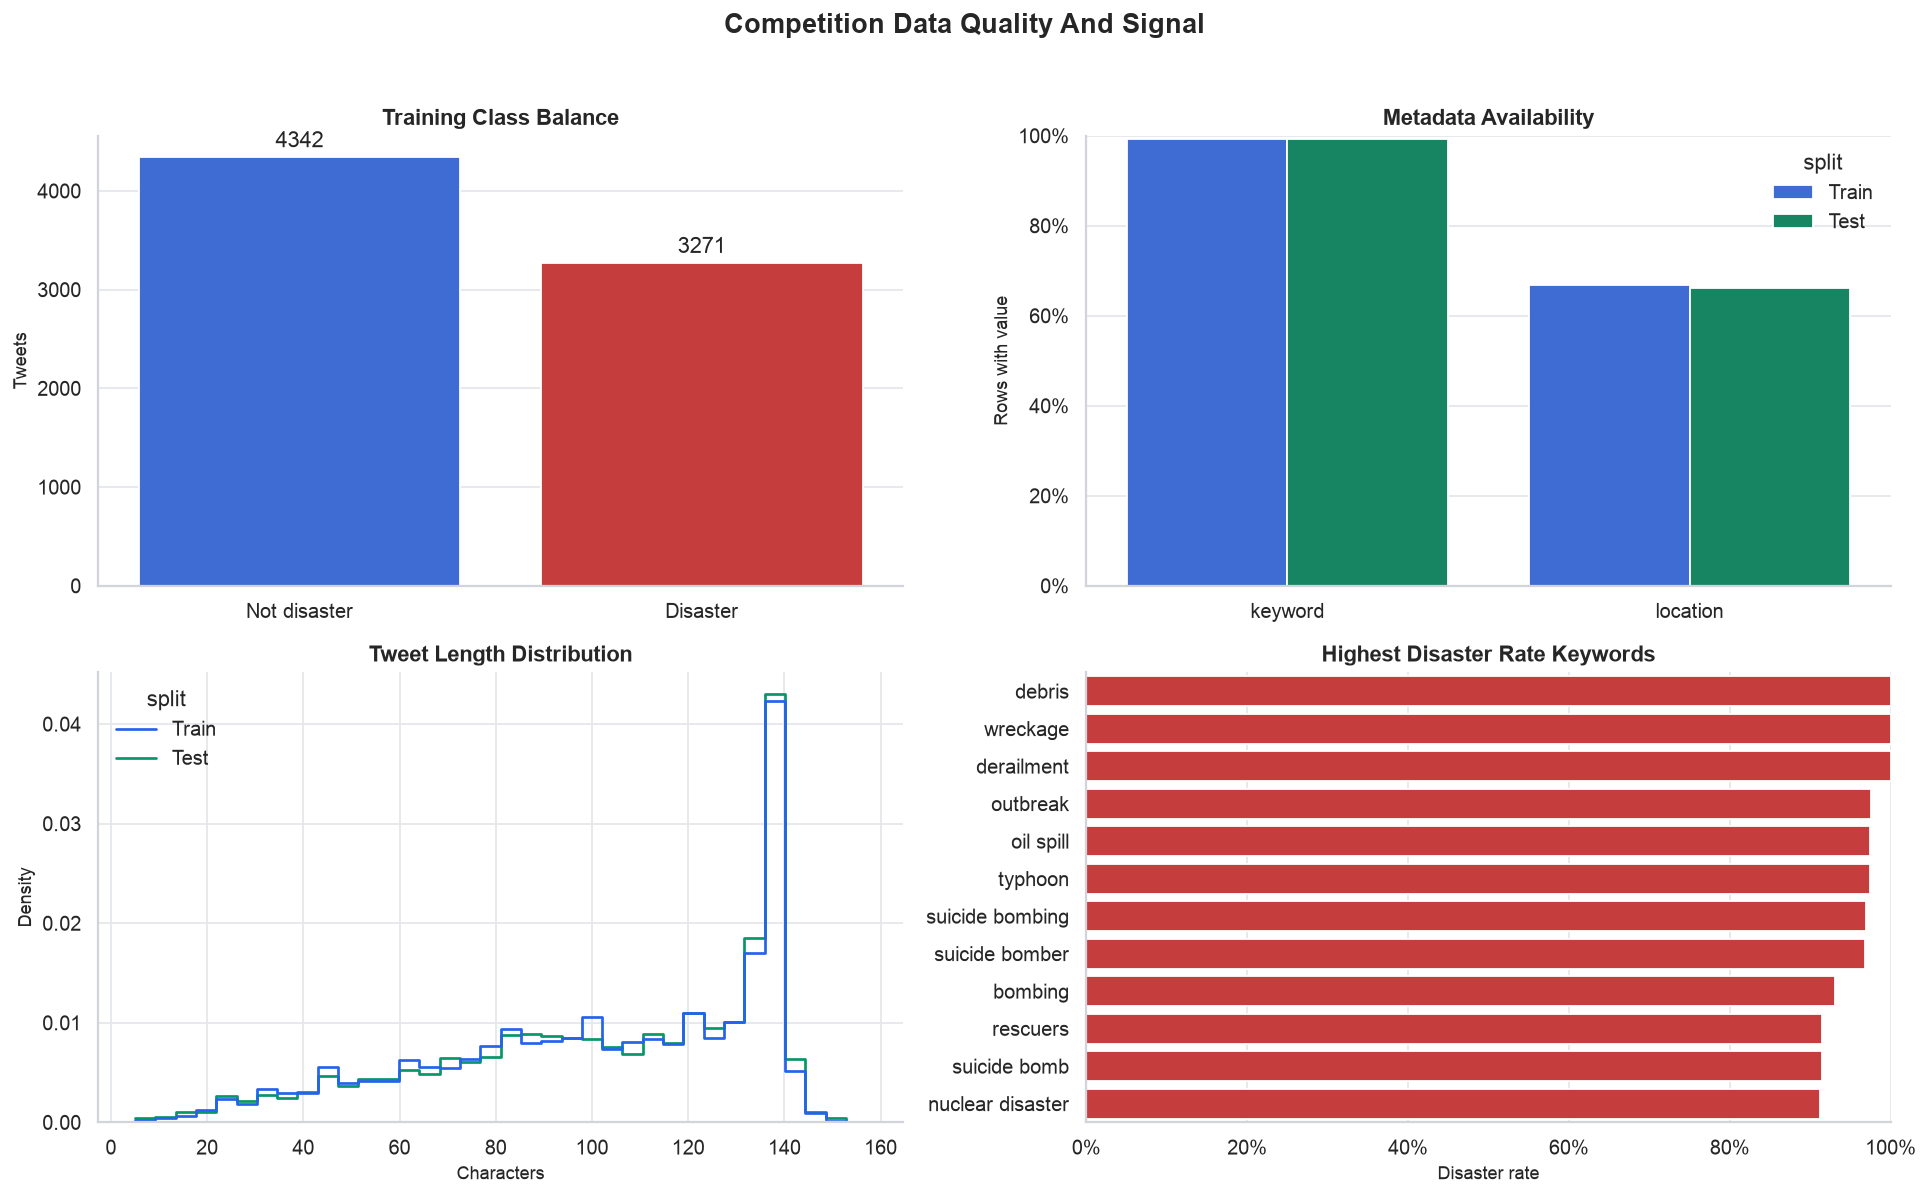

In [4]:
# Codex visualization block: dataset overview
try:
    _viz_root = ROOT
except NameError:
    _viz_root = Path.cwd()
    if not (_viz_root / "data/train.csv").exists() and (_viz_root.parent / "data/train.csv").exists():
        _viz_root = _viz_root.parent

train_preview = pd.read_csv(_viz_root / "data/train.csv")
test_preview = pd.read_csv(_viz_root / "data/test.csv")

train_plot = train_preview.assign(
    target_label=train_preview["target"].map({0: "Not disaster", 1: "Disaster"}),
    tweet_length=train_preview["text"].fillna("").astype(str).str.len(),
)
test_plot = test_preview.assign(
    split="Test",
    tweet_length=test_preview["text"].fillna("").astype(str).str.len(),
)

coverage = pd.DataFrame(
    [
        {
            "field": field,
            "split": "Train",
            "available_percent": train_preview[field].notna().mean() * 100,
        }
        for field in ["keyword", "location"]
    ]
    + [
        {
            "field": field,
            "split": "Test",
            "available_percent": test_preview[field].notna().mean() * 100,
        }
        for field in ["keyword", "location"]
    ]
)

lengths = pd.concat(
    [
        train_plot[["tweet_length"]].assign(split="Train"),
        test_plot[["tweet_length"]].assign(split="Test"),
    ],
    ignore_index=True,
)

keyword_stats = (
    train_preview.dropna(subset=["keyword"])
    .assign(keyword=lambda frame: frame["keyword"].astype(str).str.replace("%20", " ", regex=False))
    .groupby("keyword")
    .agg(sample_size=("target", "size"), disaster_rate=("target", "mean"))
    .query("sample_size >= 5")
    .sort_values("disaster_rate", ascending=False)
    .head(12)
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

sns.countplot(
    data=train_plot,
    x="target_label",
    hue="target_label",
    order=["Not disaster", "Disaster"],
    palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
    legend=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title("Training Class Balance")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Tweets")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%d", padding=3)

sns.barplot(
    data=coverage,
    x="field",
    y="available_percent",
    hue="split",
    palette={"Train": CLASS_COLORS["Train"], "Test": CLASS_COLORS["Test"]},
    ax=axes[0, 1],
)
axes[0, 1].set_title("Metadata Availability")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Rows with value")
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(100))
axes[0, 1].set_ylim(0, 100)

sns.histplot(
    data=lengths,
    x="tweet_length",
    hue="split",
    bins=36,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette={"Train": CLASS_COLORS["Train"], "Test": CLASS_COLORS["Test"]},
    ax=axes[1, 0],
)
axes[1, 0].set_title("Tweet Length Distribution")
axes[1, 0].set_xlabel("Characters")
axes[1, 0].set_ylabel("Density")

if keyword_stats.empty:
    axes[1, 1].text(0.5, 0.5, "No keyword groups with enough rows", ha="center", va="center")
    axes[1, 1].set_axis_off()
else:
    sns.barplot(
        data=keyword_stats,
        x="disaster_rate",
        y="keyword",
        color=CLASS_COLORS["Disaster"],
        ax=axes[1, 1],
    )
    axes[1, 1].set_title("Highest Disaster Rate Keywords")
    axes[1, 1].set_xlabel("Disaster rate")
    axes[1, 1].set_ylabel("")
    axes[1, 1].xaxis.set_major_formatter(PercentFormatter(1))
    axes[1, 1].set_xlim(0, 1)

fig.suptitle("Competition Data Quality And Signal", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()



In [5]:
@dataclass
class FoldResult:
    fold: int
    best_epoch: int
    val_f1: float
    val_auc: float
    val_threshold: float
    seconds: float

# Result summary: output for notebook cell 11
pd.DataFrame(
    {
        "field": list(FoldResult.__annotations__),
        "type": [str(value) for value in FoldResult.__annotations__.values()],
    }
)


,field,type
0,fold,int
1,best_epoch,int
2,val_f1,float
3,val_auc,float
4,val_threshold,float
5,seconds,float


In [6]:
class TweetDataset(Dataset):
    def __init__(self, encodings: dict[str, list[list[int]]], labels: np.ndarray | None = None):
        self.encodings = encodings
        self.labels = labels

    def __len__(self) -> int:
        return len(self.encodings["input_ids"])

    def __getitem__(self, index: int) -> dict[str, torch.Tensor]:
        item = {key: torch.tensor(value[index], dtype=torch.long) for key, value in self.encodings.items()}
        if self.labels is not None:
            item["labels"] = torch.tensor(int(self.labels[index]), dtype=torch.long)
        return item

# Result summary: output for notebook cell 12
_dataset_demo = TweetDataset(
    {"input_ids": [[1, 2], [3, 4, 5]], "attention_mask": [[1, 1], [1, 1, 1]]},
    np.array([0, 1]),
)
pd.DataFrame(
    {
        "dataset_rows": [len(_dataset_demo)],
        "first_item_keys": [", ".join(_dataset_demo[0].keys())],
        "first_label": [_dataset_demo[0]["labels"].item()],
    }
)


,dataset_rows,first_item_keys,first_label
0,2,"input_ids, attention_mask, labels",0


In [7]:
def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--train-path", type=Path, default=ROOT / "data/train.csv")
    parser.add_argument("--test-path", type=Path, default=ROOT / "data/test.csv")
    parser.add_argument("--model-name", default=DEFAULT_MODEL)
    # Hugging Face's default model cache lives under ``$HF_HOME/hub``.  Keeping
    # that final ``hub`` component here makes the explicit cache_dir compatible
    # with a cache populated via ``HF_HOME=<workspace>/.hf_cache``.
    parser.add_argument("--cache-dir", type=Path, default=ROOT / ".hf_cache" / "hub")
    parser.add_argument("--artifact-dir", type=Path, default=ROOT / "artifacts/bertweet")
    parser.add_argument("--output", type=Path, default=ROOT / "bertweet_submission.csv")
    parser.add_argument("--n-splits", type=int, default=3)
    parser.add_argument("--only-fold", type=int, default=None, help="Run just this zero-indexed fold.")
    parser.add_argument("--epochs", type=int, default=3)
    parser.add_argument("--batch-size", type=int, default=16)
    parser.add_argument("--max-length", type=int, default=64)
    parser.add_argument("--learning-rate", type=float, default=1.5e-5)
    parser.add_argument("--weight-decay", type=float, default=0.01)
    parser.add_argument("--warmup-ratio", type=float, default=0.06)
    parser.add_argument("--freeze-bottom-layers", type=int, default=0)
    parser.add_argument(
        "--keyword-mode",
        choices=("none", "prefix", "pair"),
        default="none",
        help="How to expose the supplied keyword to BERTweet.  'none' is the validated default.",
    )
    parser.add_argument("--patience", type=int, default=1)
    parser.add_argument("--seed", type=int, default=2027)
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument("--cpu-threads", type=int, default=min(8, os.cpu_count() or 1))
    parser.add_argument(
        "--allow-download",
        action="store_true",
        help="Permit Hugging Face downloads if the selected model is not cached.",
    )
    return parser.parse_args(args=[])

# Result summary: output for notebook cell 13
_bert_args_preview = parse_args()
pd.DataFrame(
    {
        "setting": list(vars(_bert_args_preview)),
        "default": [str(value) for value in vars(_bert_args_preview).values()],
    }
)


,setting,default
0,train_path,/Users/aftabhossain/Downloads/Competition/data...
1,test_path,/Users/aftabhossain/Downloads/Competition/data...
2,model_name,vinai/bertweet-base
3,cache_dir,/Users/aftabhossain/Downloads/Competition/.hf_...
4,artifact_dir,/Users/aftabhossain/Downloads/Competition/arti...
5,output,/Users/aftabhossain/Downloads/Competition/bert...
6,n_splits,3
7,only_fold,None
8,epochs,3
9,batch_size,16


## Runtime Utilities


In [8]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Result summary: output for notebook cell 15
set_seed(2027)
pd.DataFrame({"seed": [2027], "torch_initial_seed": [torch.initial_seed()]})


,seed,torch_initial_seed
0,2027,2027


In [9]:
def device_for_run() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

# Result summary: output for notebook cell 16
pd.DataFrame({"selection": ["CUDA", "Apple MPS", "CPU"], "available": [torch.cuda.is_available(), torch.backends.mps.is_available(), True], "chosen": [str(device_for_run()) == "cuda", str(device_for_run()) == "mps", str(device_for_run()) == "cpu"]})


,selection,available,chosen
0,CUDA,False,False
1,Apple MPS,True,True
2,CPU,True,False


In [10]:
def model_license(model_name: str) -> str:
    if model_name.startswith("vinai/bertweet"):
        return "MIT (see Hugging Face model card)"
    if model_name.startswith("crisistransformers/CT-M3"):
        return "Apache-2.0 (see Hugging Face model card)"
    return "See the selected Hugging Face model card."

# Result summary: output for notebook cell 17
pd.DataFrame(
    {
        "model_family": ["vinai/bertweet-base", "other Hugging Face model"],
        "license_reference": [model_license("vinai/bertweet-base"), model_license("roberta-base")],
    }
)


,model_family,license_reference
0,vinai/bertweet-base,MIT (see Hugging Face model card)
1,other Hugging Face model,See the selected Hugging Face model card.


In [11]:
def tokenizer_for_model(args: argparse.Namespace):
    tokenizer_args = {
        "cache_dir": str(args.cache_dir),
        "local_files_only": not args.allow_download,
    }
    # BERTweet's author-provided tokenizer normalizes tweet-specific URL and
    # mention forms.  CT-M3 owns a distinct byte-level BPE tokenizer, so
    # passing BERTweet-only normalization options to it would be inappropriate.
    if args.model_name.startswith("vinai/bertweet"):
        tokenizer_args["normalization"] = True
    return AutoTokenizer.from_pretrained(args.model_name, **tokenizer_args)

# Result summary: output for notebook cell 18
pd.DataFrame(
    {
        "model": ["vinai/bertweet-base"],
        "tokenizer_setup": ["BERTweet tokenizer with normalization enabled"],
        "license": [model_license("vinai/bertweet-base")],
    }
)


,model,tokenizer_setup,license
0,vinai/bertweet-base,BERTweet tokenizer with normalization enabled,MIT (see Hugging Face model card)


## Tweet Preparation


In [12]:
def clean_optional(value: object) -> str:
    if pd.isna(value):
        return ""
    return unquote_plus(str(value)).strip()

# Result summary: output for notebook cell 20
pd.DataFrame(
    {
        "raw_value": [None, "New%20York"],
        "cleaned_value": [clean_optional(None), clean_optional("New%20York")],
    }
)


,raw_value,cleaned_value
0,NaN,
1,New%20York,New York


In [13]:
def model_text(frame: pd.DataFrame, keyword_mode: str = "none") -> list[str]:
    """Keep the tweet intact and append the competition keyword as context.

    The supplied keyword is a feature available for both train and test.  We
    deliberately omit raw location: sparse-model OOF tests show it is noisy,
    whereas the keyword consistently adds signal.
    """
    tweets = frame["text"].fillna("").astype(str)
    if keyword_mode in {"none", "pair"}:
        return tweets.tolist()
    keywords = frame["keyword"].map(clean_optional)
    return [
        f"Keyword: {keyword}. Tweet: {tweet}" if keyword else tweet
        for tweet, keyword in zip(tweets, keywords, strict=True)
    ]

# Result summary: output for notebook cell 21
_text_demo = pd.DataFrame({"text": ["Flood warning", "Safe route"], "keyword": ["flood", None]})
pd.DataFrame(
    {
        "plain_text": model_text(_text_demo),
        "keyword_context": model_text(_text_demo, keyword_mode="append"),
    }
)


,plain_text,keyword_context
0,Flood warning,Keyword: flood. Tweet: Flood warning
1,Safe route,Safe route


In [14]:
def keyword_pairs(frame: pd.DataFrame) -> list[str]:
    return [
        f"topic: {keyword}" if keyword else "topic: unknown"
        for keyword in frame["keyword"].map(clean_optional)
    ]

# Result summary: output for notebook cell 22
_keyword_demo = pd.DataFrame({"keyword": ["flood", None], "location": ["New York", "London"]})
pd.DataFrame({"keyword_location_pair": keyword_pairs(_keyword_demo)})


,keyword_location_pair
0,topic: flood
1,topic: unknown


In [15]:
def encode_texts(
    tokenizer,
    texts: list[str],
    max_length: int,
    text_pairs: list[str] | None = None,
) -> dict[str, list[list[int]]]:
    return tokenizer(
        texts,
        text_pair=text_pairs,
        truncation="only_first" if text_pairs is not None else True,
        max_length=max_length,
        padding=False,
        return_attention_mask=True,
    )

# Result summary: output for notebook cell 23
pd.DataFrame(
    {
        "input": ["texts", "optional text_pairs", "max_length"],
        "encoding_effect": ["token IDs and attention masks", "paired context truncated only on the first sequence", "caps sequence length"],
    }
)


,input,encoding_effect
0,texts,token IDs and attention masks
1,optional text_pairs,paired context truncated only on the first seq...
2,max_length,caps sequence length


In [16]:
def make_loader(
    encodings: dict[str, list[list[int]]],
    labels: np.ndarray | None,
    collator: DataCollatorWithPadding,
    batch_size: int,
    shuffle: bool,
    num_workers: int,
) -> DataLoader:
    return DataLoader(
        TweetDataset(encodings, labels),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        collate_fn=collator,
        pin_memory=False,
    )

# Result summary: output for notebook cell 24
pd.DataFrame(
    {
        "loader_setting": ["batch_size", "shuffle", "collation"],
        "purpose": ["controls memory and throughput", "randomizes training batches when enabled", "pads variable-length token sequences"],
    }
)


,loader_setting,purpose
0,batch_size,controls memory and throughput
1,shuffle,randomizes training batches when enabled
2,collation,pads variable-length token sequences


## Training And Evaluation


In [17]:
def move_batch(batch: dict[str, torch.Tensor], device: torch.device) -> dict[str, torch.Tensor]:
    return {name: tensor.to(device) for name, tensor in batch.items()}

# Result summary: output for notebook cell 26
_batch_demo = {"input_ids": torch.tensor([[1, 2]]), "labels": torch.tensor([1])}
_moved_demo = move_batch(_batch_demo, torch.device("cpu"))
pd.DataFrame({"tensor": list(_moved_demo), "shape": [tuple(value.shape) for value in _moved_demo.values()], "device": [str(value.device) for value in _moved_demo.values()]})


,tensor,shape,device
0,input_ids,"(1, 2)",cpu
1,labels,"(1,)",cpu


In [18]:
@torch.inference_mode()
def predict_probabilities(model, loader: DataLoader, device: torch.device) -> np.ndarray:
    model.eval()
    chunks: list[np.ndarray] = []
    for batch in loader:
        batch = move_batch(batch, device)
        batch.pop("labels", None)
        logits = model(**batch).logits
        chunks.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(chunks)

# Result summary: output for notebook cell 27
pd.DataFrame(
    {
        "return_value": ["numpy.ndarray"],
        "meaning": ["Positive-class probabilities in original loader order"],
    }
)


,return_value,meaning
0,numpy.ndarray,Positive-class probabilities in original loade...


In [19]:
def best_f1_threshold(labels: np.ndarray, probabilities: np.ndarray) -> tuple[float, float]:
    # A fine, bounded grid is stable for this small competition and avoids
    # choosing a threshold from the test distribution.
    thresholds = np.arange(0.20, 0.801, 0.0025)
    scores = [f1_score(labels, probabilities >= threshold) for threshold in thresholds]
    best_index = int(np.argmax(scores))
    return float(thresholds[best_index]), float(scores[best_index])

# Result summary: output for notebook cell 28
_bert_threshold_labels = np.array([0, 0, 1, 1])
_bert_threshold_probabilities = np.array([0.10, 0.35, 0.60, 0.90])
_bert_threshold, _bert_score = best_f1_threshold(_bert_threshold_labels, _bert_threshold_probabilities)
pd.DataFrame({"best_threshold": [_bert_threshold], "f1": [_bert_score]})


,best_threshold,f1
0,0.35,1.0


In [20]:
def freeze_lower_encoder_layers(model, count: int) -> None:
    if count <= 0:
        return
    for parameter in model.roberta.embeddings.parameters():
        parameter.requires_grad = False
    for layer in model.roberta.encoder.layer[:count]:
        for parameter in layer.parameters():
            parameter.requires_grad = False

# Result summary: output for notebook cell 29
pd.DataFrame(
    {
        "parameter_group": ["lower encoder layers", "classification head"],
        "training_state": ["frozen according to count", "remains trainable"],
    }
)


,parameter_group,training_state
0,lower encoder layers,frozen according to count
1,classification head,remains trainable


In [21]:
def train_fold(
    *,
    fold: int,
    train_indices: np.ndarray,
    validation_indices: np.ndarray,
    labels: np.ndarray,
    train_encodings: dict[str, list[list[int]]],
    test_encodings: dict[str, list[list[int]]],
    tokenizer,
    args: argparse.Namespace,
    device: torch.device,
) -> tuple[np.ndarray, np.ndarray, FoldResult]:
    set_seed(args.seed + fold)
    local_only = not args.allow_download
    model = AutoModelForSequenceClassification.from_pretrained(
        args.model_name,
        num_labels=2,
        cache_dir=str(args.cache_dir),
        local_files_only=local_only,
    ).to(device)
    freeze_lower_encoder_layers(model, args.freeze_bottom_layers)

    collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8 if device.type == "cuda" else None)
    train_loader = make_loader(
        {key: [value[i] for i in train_indices] for key, value in train_encodings.items()},
        labels[train_indices],
        collator,
        args.batch_size,
        True,
        args.num_workers,
    )
    validation_loader = make_loader(
        {key: [value[i] for i in validation_indices] for key, value in train_encodings.items()},
        labels[validation_indices],
        collator,
        args.batch_size,
        False,
        args.num_workers,
    )
    test_loader = make_loader(
        test_encodings,
        None,
        collator,
        args.batch_size,
        False,
        args.num_workers,
    )

    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = AdamW(trainable, lr=args.learning_rate, weight_decay=args.weight_decay)
    total_steps = len(train_loader) * args.epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, round(total_steps * args.warmup_ratio)),
        num_training_steps=total_steps,
    )

    best_validation_probability: np.ndarray | None = None
    best_test_probability: np.ndarray | None = None
    best_epoch = 0
    best_score = -np.inf
    best_threshold = 0.5
    stale_epochs = 0
    started = time.perf_counter()

    for epoch in range(1, args.epochs + 1):
        model.train()
        losses: list[float] = []
        for step, batch in enumerate(train_loader, start=1):
            optimizer.zero_grad(set_to_none=True)
            batch = move_batch(batch, device)
            result = model(**batch)
            result.loss.backward()
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            optimizer.step()
            scheduler.step()
            losses.append(float(result.loss.detach().cpu()))
            if step % 100 == 0 or step == len(train_loader):
                print(
                    f"fold={fold} epoch={epoch} batch={step}/{len(train_loader)} "
                    f"mean_loss={np.mean(losses):.4f}",
                    flush=True,
                )

        validation_probability = predict_probabilities(model, validation_loader, device)
        threshold, score = best_f1_threshold(labels[validation_indices], validation_probability)
        auc = roc_auc_score(labels[validation_indices], validation_probability)
        print(
            f"fold={fold} epoch={epoch} loss={np.mean(losses):.4f} "
            f"val_f1={score:.5f} val_auc={auc:.5f} threshold={threshold:.3f}",
            flush=True,
        )

        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_threshold = threshold
            best_validation_probability = validation_probability
            best_test_probability = predict_probabilities(model, test_loader, device)
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs > args.patience:
                print(f"fold={fold} early stop after epoch={epoch}", flush=True)
                break

    elapsed = time.perf_counter() - started
    assert best_validation_probability is not None and best_test_probability is not None
    result = FoldResult(
        fold=fold,
        best_epoch=best_epoch,
        val_f1=float(best_score),
        val_auc=float(roc_auc_score(labels[validation_indices], best_validation_probability)),
        val_threshold=float(best_threshold),
        seconds=float(elapsed),
    )
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return best_validation_probability, best_test_probability, result

# Result summary: output for notebook cell 30
pd.DataFrame(
    {
        "return_value": ["validation_probability", "test_probability", "FoldResult"],
        "purpose": ["OOF probabilities for threshold selection", "test probabilities for blending", "fold-level timing and metrics"],
    }
)


,return_value,purpose
0,validation_probability,OOF probabilities for threshold selection
1,test_probability,test probabilities for blending
2,FoldResult,fold-level timing and metrics


## Pipeline Entry Point


In [22]:
def main() -> None:
    args = parse_args()
    if args.n_splits < 2:
        raise ValueError("--n-splits must be at least 2")
    if args.only_fold is not None and not 0 <= args.only_fold < args.n_splits:
        raise ValueError("--only-fold must be between 0 and n_splits - 1")
    if args.epochs < 1 or args.batch_size < 1:
        raise ValueError("--epochs and --batch-size must be positive")

    args.cache_dir.mkdir(parents=True, exist_ok=True)
    args.artifact_dir.mkdir(parents=True, exist_ok=True)
    torch.set_num_threads(args.cpu_threads)
    set_seed(args.seed)
    device = device_for_run()
    print(f"device={device.type} torch_threads={torch.get_num_threads()}", flush=True)

    train = pd.read_csv(args.train_path)
    test = pd.read_csv(args.test_path)
    labels = train["target"].astype(int).to_numpy()
    print(f"train_rows={len(train)} test_rows={len(test)} positive_rate={labels.mean():.4f}", flush=True)

    # Passing local_files_only avoids accidental Hub calls once the approved
    # weights are cached.  --allow-download is an explicit opt-in for a fresh
    # setup.
    tokenizer = tokenizer_for_model(args)
    train_encodings = encode_texts(
        tokenizer,
        model_text(train, keyword_mode=args.keyword_mode),
        args.max_length,
        keyword_pairs(train) if args.keyword_mode == "pair" else None,
    )
    test_encodings = encode_texts(
        tokenizer,
        model_text(test, keyword_mode=args.keyword_mode),
        args.max_length,
        keyword_pairs(test) if args.keyword_mode == "pair" else None,
    )

    splitter = StratifiedKFold(args.n_splits, shuffle=True, random_state=args.seed)
    oof_probability = np.full(len(train), np.nan, dtype=np.float64)
    test_probability = np.zeros(len(test), dtype=np.float64)
    fold_results: list[FoldResult] = []
    completed_folds = 0

    for fold, (train_indices, validation_indices) in enumerate(splitter.split(train, labels)):
        if args.only_fold is not None and fold != args.only_fold:
            continue
        print(
            f"\nstarting fold={fold} train={len(train_indices)} validation={len(validation_indices)}",
            flush=True,
        )
        validation_probability, fold_test_probability, result = train_fold(
            fold=fold,
            train_indices=train_indices,
            validation_indices=validation_indices,
            labels=labels,
            train_encodings=train_encodings,
            test_encodings=test_encodings,
            tokenizer=tokenizer,
            args=args,
            device=device,
        )
        oof_probability[validation_indices] = validation_probability
        test_probability += fold_test_probability
        fold_results.append(result)
        completed_folds += 1
        print(
            f"completed fold={fold} best_epoch={result.best_epoch} "
            f"val_f1={result.val_f1:.5f} elapsed={result.seconds / 60:.1f}m",
            flush=True,
        )

    if completed_folds == 0:
        raise RuntimeError("No folds were selected.")
    test_probability /= completed_folds

    metadata = {
        "model": args.model_name,
        "model_license": model_license(args.model_name),
        "data_provenance": "Only data/train.csv labels; no test targets or manual labels.",
        "arguments": {key: str(value) if isinstance(value, Path) else value for key, value in vars(args).items()},
        "folds": [asdict(result) for result in fold_results],
    }

    # Single-fold mode is for smoke tests only: it deliberately avoids writing
    # a final submission whose threshold was selected from incomplete OOF data.
    if completed_folds != args.n_splits:
        (args.artifact_dir / "smoke_test_metadata.json").write_text(json.dumps(metadata, indent=2))
        np.savez_compressed(
            args.artifact_dir / "smoke_test_predictions.npz",
            oof_probability=oof_probability,
            test_probability=test_probability,
        )
        print("Single-fold smoke test complete; no submission written.", flush=True)
        return

    threshold, oof_f1 = best_f1_threshold(labels, oof_probability)
    oof_auc = roc_auc_score(labels, oof_probability)
    predictions = (test_probability >= threshold).astype(int)
    submission = pd.DataFrame({"id": test["id"], "target": predictions})
    args.output.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(args.output, index=False)

    metadata.update(
        {
            "oof_f1": float(oof_f1),
            "oof_auc": float(oof_auc),
            "decision_threshold": float(threshold),
            "test_positive_count": int(predictions.sum()),
            "test_positive_rate": float(predictions.mean()),
            "output": str(args.output),
        }
    )
    (args.artifact_dir / "run_metadata.json").write_text(json.dumps(metadata, indent=2))
    np.savez_compressed(
        args.artifact_dir / "predictions.npz",
        oof_probability=oof_probability,
        test_probability=test_probability,
    )
    print(
        f"OOF F1={oof_f1:.5f} AUC={oof_auc:.5f} threshold={threshold:.3f} | "
        f"submission={args.output} positives={predictions.sum()}/{len(predictions)}",
        flush=True,
    )

# Result summary: output for notebook cell 32
pd.DataFrame(
    {
        "pipeline_stage": ["tokenize", "fine_tune", "validate", "write"],
        "artifact": ["BERTweet input tensors", "fold checkpoints", "OOF F1 and threshold", "prediction and metadata files"],
    }
)


,pipeline_stage,artifact
0,tokenize,BERTweet input tensors
1,fine_tune,fold checkpoints
2,validate,OOF F1 and threshold
3,write,prediction and metadata files


## Execute

Review the defaults in `parse_args()` first. Uncomment `main()` when you want the notebook to run the full pipeline and write artifacts.


In [23]:
# main()

# Result summary: output for notebook cell 34
_bert_preflight = pd.DataFrame(
    {
        "path": [ROOT / "data/train.csv", ROOT / "data/test.csv", ROOT / "artifacts/bertweet_full"],
    }
)
_bert_preflight["exists"] = _bert_preflight["path"].map(Path.exists)
_bert_preflight


,path,exists
0,/Users/aftabhossain/Downloads/Competition/data...,True
1,/Users/aftabhossain/Downloads/Competition/data...,True
2,/Users/aftabhossain/Downloads/Competition/arti...,True


## Artifact Visual Diagnostics

Run this after generating prediction artifacts. The plots show OOF class separation, F1 sensitivity by threshold, and train/test probability distributions.


Best OOF F1=0.81300 at threshold=0.435


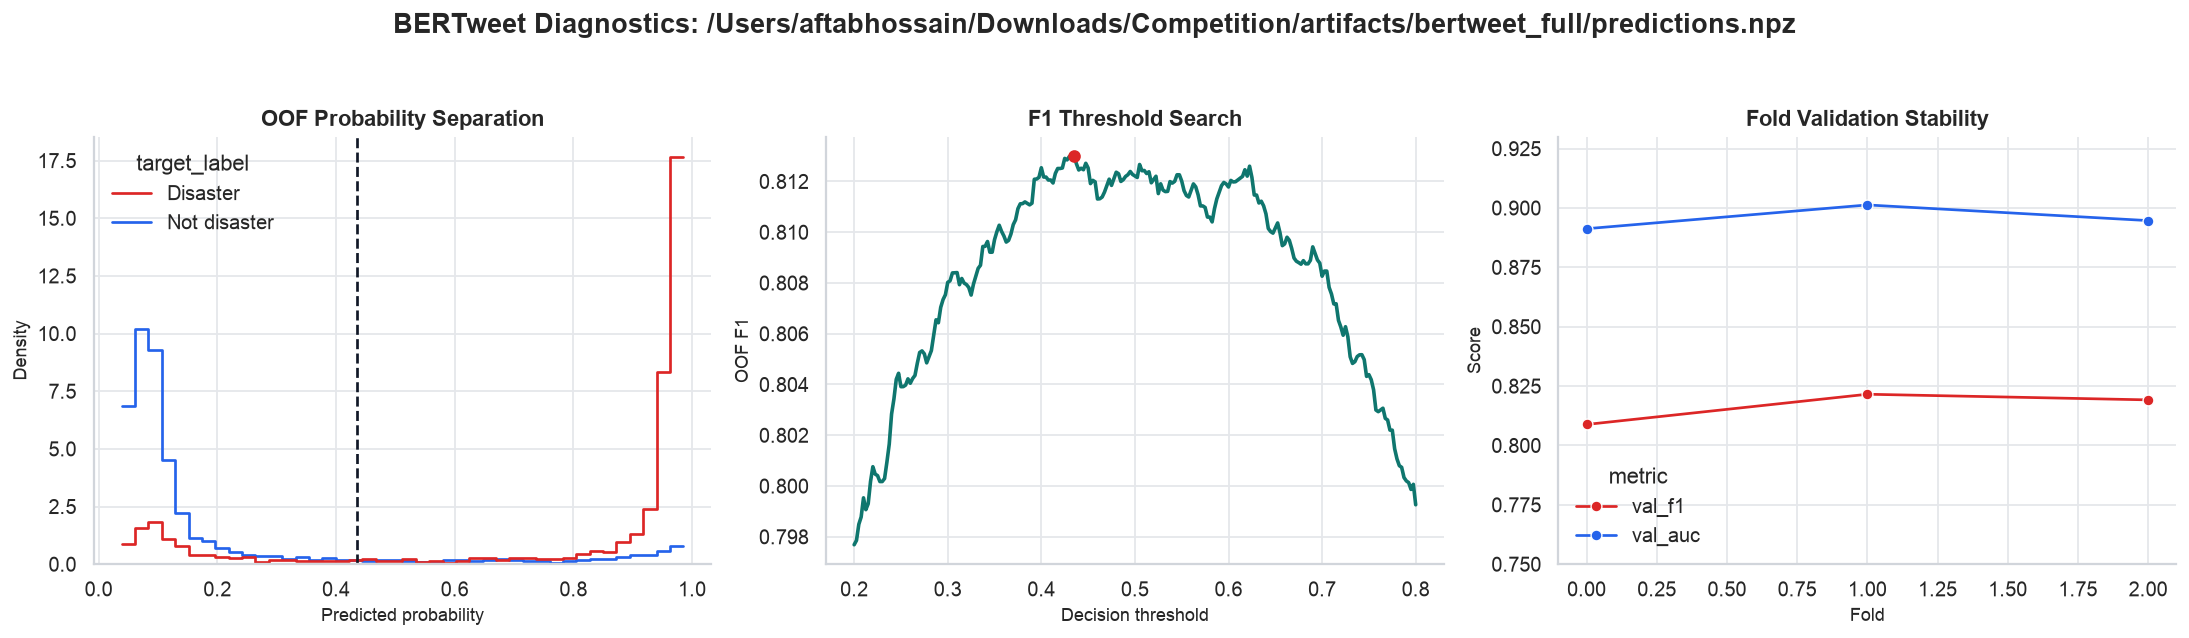

In [24]:
def _first_existing(paths: list[Path]) -> Path | None:
    return next((path for path in paths if path.exists()), None)

artifact_path = _first_existing(
    [
        ROOT / "artifacts/bertweet_full/predictions.npz",
        ROOT / "artifacts/bertweet_seed99173/predictions.npz",
    ]
)

if artifact_path is None:
    print("No BERTweet prediction artifact found yet. Run the fine-tuning pipeline first, then rerun this diagnostics cell.")
else:
    train_labels = pd.read_csv(ROOT / "data/train.csv")["target"].astype(int).to_numpy()
    artifact = np.load(artifact_path)
    oof_probability = np.asarray(artifact["oof_probability"], dtype=float)
    test_probability = np.asarray(artifact["test_probability"], dtype=float)

    if len(oof_probability) != len(train_labels):
        print(f"Skipping {artifact_path}: expected {len(train_labels):,} OOF rows, found {len(oof_probability):,}.")
    else:
        threshold, score = best_f1_threshold(train_labels, oof_probability)
        threshold_grid = np.arange(0.20, 0.801, 0.0025)
        f1_curve = [f1_score(train_labels, oof_probability >= value) for value in threshold_grid]
        metadata_path = artifact_path.with_name("run_metadata.json")
        metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}
        fold_frame = pd.DataFrame(metadata.get("folds", []))
        oof_frame = pd.DataFrame(
            {
                "probability": oof_probability,
                "target_label": np.where(train_labels == 1, "Disaster", "Not disaster"),
            }
        )

        fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

        sns.histplot(
            data=oof_frame,
            x="probability",
            hue="target_label",
            bins=42,
            stat="density",
            common_norm=False,
            element="step",
            fill=False,
            palette={"Not disaster": CLASS_COLORS["Not disaster"], "Disaster": CLASS_COLORS["Disaster"]},
            ax=axes[0],
        )
        axes[0].axvline(threshold, color="#111827", linestyle="--", linewidth=1.5)
        axes[0].set_title("OOF Probability Separation")
        axes[0].set_xlabel("Predicted probability")
        axes[0].set_ylabel("Density")

        axes[1].plot(threshold_grid, f1_curve, color="#0f766e", linewidth=2)
        axes[1].scatter([threshold], [score], color="#dc2626", zorder=3)
        axes[1].set_title("F1 Threshold Search")
        axes[1].set_xlabel("Decision threshold")
        axes[1].set_ylabel("OOF F1")

        if fold_frame.empty:
            axes[2].text(0.5, 0.5, "No fold metadata found", ha="center", va="center")
            axes[2].set_axis_off()
        else:
            fold_long = fold_frame.melt(
                id_vars="fold",
                value_vars=["val_f1", "val_auc"],
                var_name="metric",
                value_name="score",
            )
            sns.lineplot(
                data=fold_long,
                x="fold",
                y="score",
                hue="metric",
                marker="o",
                palette={"val_f1": "#dc2626", "val_auc": "#2563eb"},
                ax=axes[2],
            )
            axes[2].set_title("Fold Validation Stability")
            axes[2].set_xlabel("Fold")
            axes[2].set_ylabel("Score")
            axes[2].set_ylim(0.75, 0.93)

        fig.suptitle(f"BERTweet Diagnostics: {artifact_path}", fontsize=15, fontweight="bold", y=1.04)
        plt.tight_layout()
        print(f"Best OOF F1={score:.5f} at threshold={threshold:.3f}")

